# Linearized LLG equation

Following the corrected notes, construct $\mathbf n(i),R(i),E(i),\mathbf g_{\rm eff}(i),H^0_{ij},K_{ij},D(\mathbf k)$ in order.
Prepare the NiI2 lattice from Step 5 first, then follow Steps 1-4. The magnetic cell contains seven spins by default. This notebook does not perform LLG relaxation.

Use $\Xi(\mathbf L,t)=\Xi_0e^{i\mathbf k\cdot\mathbf L-i\omega t}$.
Keep the notation from the notes: $K_{ij}=E(i)^TH^0_{ij}E(j)$ excludes the constraint correction, and **$D$ excludes $1/\hbar$**, so
$$D(\mathbf k)\Xi=-i\hbar\omega\Xi.$$
The final two plotting cells show the energy spectrum and growth rate separately.

## Preparation: load the configuration and parameters from one MUC file

`muc_file` points to `magnetic_unit_cell.json` in the MC results folder. The spin configuration, 7-by-1 size, and Hamiltonian all come from this file.
To use another saved MC run, change this path.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from nix2_llg import HBAR_MEV_PS

np.set_printoptions(precision=5, suppress=True)
hbar = HBAR_MEV_PS
mu_s = 0.1157676  # meV/T, g=2 and S=1
muc_file = Path("MC_results/NiI2_PRL_REALISTIC_Model_ANNEALING_20261027_120435_366599/magnetic_unit_cell.json")
muc_data = json.loads(muc_file.read_text(encoding="utf-8"))
model = muc_data["model"]
lattice_muc = muc_data["lattice"]
A = float(model["A_ani_meV"][0])
B = float(model["B_biquad"])
h_field = np.array(model["zeeman_meV"])
print("Loaded:", muc_file)
print("A, B [meV] =", A, B)

Loaded: MC_results\NiI2_PRL_REALISTIC_Model_ANNEALING_20261027_120435_366599\magnetic_unit_cell.json
A, B [meV] = 0.14 -0.719


## Step 5 (preparation): magnetic unit cell and neighbors

Use $\mathbf a_1=a(\sqrt3/2,-1/2),\mathbf a_2=a(0,1)$, $\mathbf A_1=N\mathbf a_1,\mathbf A_2=\mathbf a_2$, and $\mathbf r_i=i\mathbf a_1$.
Represent each bond displacement as $p\mathbf a_1+q\mathbf a_2$:

| Neighbors | $(p,q)$ |
|---|---|
| NN | $(0,\pm1),(1,0),(1,1),(-1,0),(-1,-1)$ |
| 2NN | $(1,-1),(1,2),(-1,1),(-1,-2),(2,1),(-2,-1)$ |
| 3NN | $(0,\pm2),(2,0),(2,2),(-2,0),(-2,-2)$ |

`divmod(i+p, N)` gives the cell offset and site index: $\mathbf L=m_1\mathbf A_1+q\mathbf A_2$. Each entry in `bonds` is `(i,j,(m1,m2),Jij,Bij)`, with both bond directions included.
Load all stored bonds directly. The current model has $J_2=0$ and includes NN and 3NN bonds. This describes a two-dimensional triangular lattice, not a one-dimensional chain.

**N=7 means seven Ni spins.** The rectangular MC lattice `7 x 1 x 2` contains 14 Ni spins. A configuration whose full period is seven rectangular cells, with repetition along y, would require `N=14`.

In [2]:
N = lattice_muc["Nx"]  # 7 spins, one primitive sublattice
a1, a2 = np.array(lattice_muc["a_vectors"])
A1, A2 = np.array(lattice_muc["magnetic_vectors"])
B1, B2 = 2 * np.pi * np.linalg.inv(np.array([A1, A2])).T
positions = np.array(lattice_muc["positions"])

# Stored tensors use the source rectangular basis (two equivalent Ni sites).
# Convert offsets to the primitive basis a1=(sqrt(3)/2,-1/2), a2=(0,1).
neighbors = []
for b in range(model["num_bonds"][0]):
    target, dx, dy = model["bond_vectors"][0][b]
    p, q = 2*dx + target, dy + dx + target
    Jij = np.array(model["bond_matrices_meV"][0][b])
    Bij = B if b in model["biquadratic_bond_indices"] else 0.0
    neighbors.append((p, q, Jij, Bij))

bonds = []
for i in range(N):
    for p, q, Jij, Bij in neighbors:
        m1, j = divmod(i + p, N)
        bonds.append((i, j, (m1, q), Jij, Bij))

print("Magnetic cell:", (N, lattice_muc["Ny"]), "; spins:", N)
print("A1, A2 =", A1, A2)
print("B1, B2 =", B1, B2)

Magnetic cell: (7, 1) ; spins: 7
A1, A2 = [ 6.06218 -3.5    ] [0. 1.]
B1, B2 = [1.03646 0.     ] [3.6276  6.28319]


## Step 1a: load $\mathbf S^{(0)}(i)=\mathbf n(i)$

`S0` comes directly from `spin_config_muc` in the same file and includes all x, y, and z components. The ordering corresponds to $i\mathbf a_1$, equivalent to the original zigzag positions modulo integer multiples of $\mathbf a_2$.
This is an LLG-relaxed candidate ground state. The following cells report the torque and examine mode stability; convergence alone does not establish a global energy minimum.

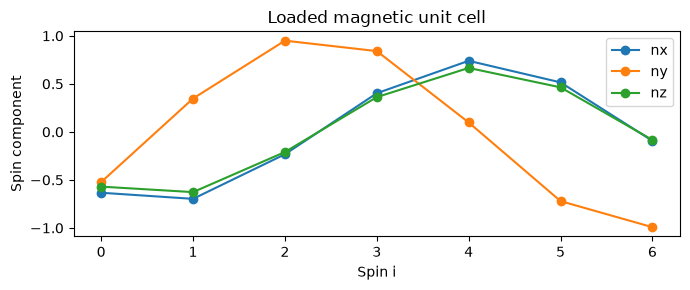

In [3]:
S0 = np.array(muc_data["spin_config_muc"], dtype=float)

n = S0 / np.linalg.norm(S0, axis=1, keepdims=True)
theta = np.arccos(np.clip(n[:, 2], -1, 1))
phi = np.arctan2(n[:, 1], n[:, 0])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(N), n, "o-")
ax.legend(["nx", "ny", "nz"])
ax.set(xlabel="Spin i", ylabel="Spin component", title="Loaded magnetic unit cell")
plt.tight_layout()
plt.show()

## Step 1b: $R(i)$ and $E(i)$

Use the spherical-coordinate basis from the notes: $R(i)=(\mathbf e_1(i),\mathbf e_2(i),\mathbf n(i))$ and $E(i)=(\mathbf e_1(i),\mathbf e_2(i))$.
`R[i]` has shape $3\times3$ and `E[i]` has shape $3\times2$. Their columns contain the basis vectors in global coordinates, with $\mathbf e_1\times\mathbf e_2=\mathbf n$.
`P` maps the magnetic-cell amplitudes $\Xi=(\xi_1(0),\xi_2(0),\ldots)^T$ to global spin components.

In [4]:
e1 = np.column_stack([np.cos(theta)*np.cos(phi),
                      np.cos(theta)*np.sin(phi), -np.sin(theta)])
e2 = np.column_stack([-np.sin(phi), np.cos(phi), np.zeros(N)])
R = np.stack([e1, e2, n], axis=2)  # basis vectors are columns
E = R[:, :, :2].copy()
P = np.zeros((3*N, 2*N))
for i in range(N):
    P[3*i:3*i+3, 2*i:2*i+2] = E[i]
print("R(0) =\n", R[0])

R(0) =
 [[ 0.43966  0.63648 -0.63371]
 [ 0.36281 -0.77129 -0.52295]
 [-0.82163  0.      -0.57003]]


## Step 2a: $\mathbf g_{\rm eff}(i)$ and $\lambda_i$

$$\mathcal H=\tfrac12\sum_{i,j,\mathbf L}[\mathbf S_i^TJ_{ij}\mathbf S_j+B_{ij}(\mathbf S_i\cdot\mathbf S_j)^2]+A\sum_i(S_i^z)^2-\sum_i\mathbf h\cdot\mathbf S_i.$$
$$\mathbf g_{\rm eff}(i)=\sum_{j,\mathbf L}[J_{ij}\mathbf n_j+2B_{ij}(\mathbf n_i\cdot\mathbf n_j)\mathbf n_j]+2An_i^z\hat z-\mathbf h,\quad\lambda_i=\mathbf n_i\cdot\mathbf g_{\rm eff}(i).$$
The factor $1/2$ in the energy avoids double-counting directed bonds. The gradient already combines contributions from both ends and has no factor $1/2$. Report the maximum torque to check how close the input is to equilibrium.

In [5]:
def energy_per_cell(spins):
    energy = A*np.sum(spins[:, 2]**2) - np.sum(spins @ h_field)
    for i, j, L, Jij, Bij in bonds:
        energy += 0.5 * (spins[i] @ Jij @ spins[j] + Bij*(spins[i] @ spins[j])**2)
    return energy

def gradient(spins):
    g = np.tile(-h_field, (N, 1))
    g[:, 2] += 2*A*spins[:, 2]
    for i, j, L, Jij, Bij in bonds:
        g[i] += Jij @ spins[j] + 2*Bij*(spins[i] @ spins[j])*spins[j]
    return g

g_eff = gradient(n)
lambda_i = np.sum(n * g_eff, axis=1)
B_eff = -g_eff / mu_s
max_torque = np.max(np.linalg.norm(np.cross(n, g_eff), axis=1))
print("Energy per magnetic cell [meV] =", energy_per_cell(n))
print("g_eff [meV] =\n", g_eff)
print("lambda_i [meV] =", lambda_i)
print("Max |n x g_eff| [meV] =", max_torque)

Energy per magnetic cell [meV] = -75.5654260563354
g_eff [meV] =
 [[ 15.24608  12.58135  13.71395]
 [ 16.73335  -8.33515  15.05232]
 [  5.66319 -23.0738    5.09334]
 [ -9.74375 -20.37225  -8.76367]
 [-17.7272   -2.34878 -15.94677]
 [-12.44464  17.41086 -11.19338]
 [  2.27291  24.13768   2.04416]]
lambda_i [meV] = [-24.05838 -24.00108 -24.29843 -24.22336 -23.95976 -24.15158 -24.33048]
Max |n x g_eff| [meV] = 1.1556197923289105e-12


## Step 2b: Cartesian Hessian $H^0_{\alpha\beta}\langle(0,i),(\mathbf L,j)\rangle$

`H0[(m1,m2)]` is the $3N\times3N$ Hessian block for cell separation $\mathbf L=m_1\mathbf A_1+m_2\mathbf A_2$. Each site block has shape $3\times3$.
The mixed derivative for a bond is $J_{ij}+2B_{ij}[\mathbf n_j\mathbf n_i^T+(\mathbf n_i\cdot\mathbf n_j)I_3]$, with an additional onsite contribution $2B_{ij}\mathbf n_j\mathbf n_j^T$.
Even when `i==j`, spins in different cells are distinct physical sites, so intercell terms must be retained.

In [6]:
cell_indices = sorted({(0, 0)} | {L for i, j, L, Jij, Bij in bonds})
H0 = {L: np.zeros((3*N, 3*N)) for L in cell_indices}
for i in range(N):
    ii = slice(3*i, 3*i+3)
    H0[(0, 0)][ii, ii] += np.diag([0.0, 0.0, 2*A])

for i, j, L, Jij, Bij in bonds:
    ii, jj = slice(3*i, 3*i+3), slice(3*j, 3*j+3)
    c = n[i] @ n[j]
    H0[(0, 0)][ii, ii] += 2*Bij*np.outer(n[j], n[j])
    H0[L][ii, jj] += Jij + 2*Bij*(np.outer(n[j], n[i]) + c*np.eye(3))

print("H0[(0,0)] shape:", H0[(0, 0)].shape)

H0[(0,0)] shape: (21, 21)


## Step 2c: project onto $K\langle i,j\rangle$

$$K\langle(0,i),(\mathbf L,j)\rangle=E(i)^T H^0\langle(0,i),(\mathbf L,j)\rangle E(j).$$
`K[L]` has shape $2N\times2N$. **Do not subtract $\lambda_i$ here**, following the notation in the notes.
The fixed-length expansion is $\mathbf S_i=\mathbf n_i+E_i\xi_i-\tfrac12|\xi_i|^2\mathbf n_i+\cdots$, so the constrained energy curvature is $K-\Lambda$.

In [7]:
K = {L: P.T @ H0[L] @ P for L in cell_indices}
Lambda = np.diag(np.repeat(lambda_i, 2))
print("K[(0,0)] shape:", K[(0, 0)].shape)
print("K<(0,0),(0,0)> =\n", K[(0, 0)][:2, :2])

K[(0,0)] shape: (14, 14)
K<(0,0),(0,0)> =
 [[-0.45024  1.35891]
 [ 1.35891 -2.88872]]


## Step 3: linearized LLG without damping

$$J_{2\times2}=\begin{pmatrix}0&-1\\1&0\end{pmatrix},\qquad
D(\mathbf L)=(I_N\otimes J_{2\times2})[K(\mathbf L)-\delta_{\mathbf L,0}\Lambda].$$
$$\hbar\dot\Xi(\mathbf L_m)=\sum_{\mathbf L}D(\mathbf L)\Xi(\mathbf L_m+\mathbf L).$$
`D_real[L]` has units of meV. Divide by $\hbar$ when converting to a time-evolution rate. Continue with the spectrum calculation in Step 4-2, without performing the time integration in Step 4-1.
The homogeneous equation assumes zero background torque. A nonstationary input can demonstrate matrix construction but does not define equilibrium normal modes.

In [8]:
J_2x2 = np.array([[0.0, -1.0], [1.0, 0.0]])
J_big = np.kron(np.eye(N), J_2x2)
D_real = {L: J_big @ K[L] for L in cell_indices}
D_real[(0, 0)] -= J_big @ Lambda

## Step 4-2a: Bloch phase and $D(\mathbf k)$

$$\Xi(\mathbf L,t)=\Xi(0)e^{i\mathbf k\cdot\mathbf L-i\omega t},\quad
\mathbf k=k_1\mathbf B_1+k_2\mathbf B_2,\quad\mathbf A_\mu\cdot\mathbf B_\nu=2\pi\delta_{\mu\nu}.$$
$$D(\mathbf k)=\sum_{m_1,m_2}e^{i2\pi(m_1k_1+m_2k_2)}D(m_1,m_2).$$
The inputs `k1, k2` are **reduced coordinates in the magnetic reciprocal basis**. The phase uses magnetic-cell translations, not full bond displacements.
The discrete values $k_\mu=n_\mu/N_\mu$ in the notes apply to finite systems with periodic boundaries. Here the infinitely repeated magnetic lattice allows continuous k sampling, with only a $2N\times2N$ matrix at each point.

In [9]:
def dynamical_matrix(k1, k2):
    D = np.zeros((2*N, 2*N), dtype=complex)
    for (m1, m2), block in D_real.items():
        phase = np.exp(2j*np.pi*(m1*k1 + m2*k2))
        D += phase * block
    return D

k1, k2 = 0.0, 0.0
D = dynamical_matrix(k1, k2)
print("D(k) shape:", D.shape)
print("D(0,0) block [meV] =\n", D[:2, :2])

D(k) shape: (14, 14)
D(0,0) block [meV] =
 [[ -2.10207+0.j -13.3051 +0.j]
 [ 16.47184+0.j   2.10207+0.j]]


## Step 4-2b: eigenmodes and mode energies

$$D(\mathbf k)\Xi_n=d_n\Xi_n=-i\hbar\omega_n\Xi_n,\qquad\varepsilon_n=\hbar\omega_n=i d_n.$$
Use `eig` and retain all complex eigenvalues without taking absolute values. A stable background has N nonnegative-frequency branches, possibly including zero modes; in general, positive and negative partners occur at k and -k.
`P @ Xi` gives global spin amplitudes. These have not been normalized for quantum scattering intensities.

In [10]:
def solve_modes(k1, k2):
    d, Xi = np.linalg.eig(dynamical_matrix(k1, k2))
    epsilon = 1j * d  # meV: D already has energy units
    order = np.argsort(epsilon.real)
    return epsilon[order], Xi[:, order]

epsilon, Xi = solve_modes(k1, k2)
omega = epsilon / hbar
mode_index = np.argmax(epsilon.real)
delta_spin = (P @ Xi[:, mode_index]).reshape(N, 3)
print("All epsilon(k) [meV] =\n", epsilon)
print("Selected mode energy [meV] =", epsilon[mode_index])
print("Global spin amplitude =\n", delta_spin)
# Real displacement: Re[delta_spin * exp(i*k.L - i*omega*t)]

All epsilon(k) [meV] =
 [-30.3636 +0.j -30.36357+0.j -15.78359+0.j -15.78099+0.j  -2.21671-0.j
  -1.9524 -0.j  -0.     +0.j   0.     -0.j   1.9524 +0.j   2.21671-0.j
  15.78099+0.j  15.78359-0.j  30.36357-0.j  30.3636 +0.j]
Selected mode energy [meV] = (30.36359985848848+8.90232091916087e-17j)
Global spin amplitude =
 [[ 0.01131-0.01515j -0.02843+0.00282j  0.01352+0.01426j]
 [ 0.06383+0.09708j  0.20949-0.01401j  0.04504-0.11568j]
 [-0.27041-0.15417j -0.11633+0.00776j -0.22634+0.20657j]
 [ 0.28386+0.18305j -0.23718+0.0153j   0.23575-0.23909j]
 [-0.04092-0.18398j  0.41374-0.02438j -0.01545+0.20811j]
 [-0.16138+0.15298j -0.22103+0.01154j -0.16439-0.15213j]
 [ 0.1137 -0.07986j -0.02018+0.00092j  0.11186+0.07794j]]


## Step 4-2c: Candidate path inferred from the Nature 2024 source data

Use the primitive triangular-lattice path scaled by $1/N$:
$$K=\frac13 B_1+\frac{1}{3N}B_2,\qquad \Gamma=0,\qquad M=\frac12 B_1.$$
Here $b_1=NB_1$ and $b_2=B_2$. The coordinates below are in the magnetic reciprocal basis and go directly into `solve_modes`.

This candidate matches the published path lengths, but the source data only provide a one-dimensional coordinate, not explicit two-dimensional wavevectors. It is not a verified corner of the magnetic Wigner-Seitz Brillouin zone.

The horizontal axis is cumulative Cartesian k distance, shifted so that Gamma is zero. No additional affine rescaling is applied. The Hamiltonian and loaded spin configuration are unchanged.

Source: [Nature 2024 Fig. 1 source data](https://www.nature.com/articles/s41586-024-07678-5#MOESM3).


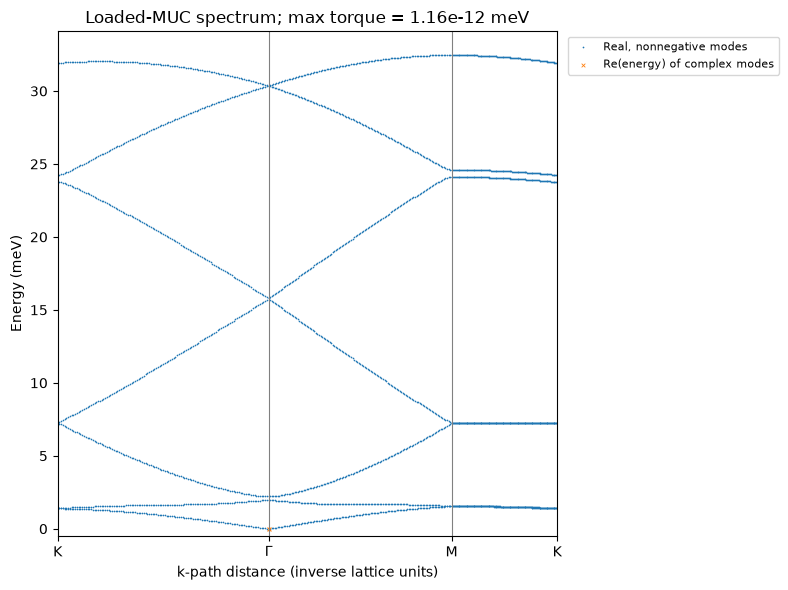

In [11]:
# Reduced coordinates in the magnetic reciprocal basis (B1, B2).
path_nodes = np.array([[1/3, 1/(3*N)], [0, 0], [1/2, 0], [1/3, 1/(3*N)]])
path_labels = ["K", r"$\Gamma$", "M", "K"]
points_per_segment = 120

# Do not repeat the shared endpoint between adjacent segments.
path_magnetic = np.vstack([
    np.linspace(start, end, points_per_segment, endpoint=False)
    for start, end in zip(path_nodes[:-1], path_nodes[1:])
] + [path_nodes[-1:]])
path_cartesian = path_magnetic @ np.array([B1, B2])
# Cartesian distance in inverse lattice units; Gamma is the origin.
path_distance = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path_cartesian, axis=0), axis=1))]
path_distance -= path_distance[points_per_segment]
node_indices = np.arange(4) * points_per_segment
path_ticks = path_distance[node_indices]

epsilon_path = np.array([solve_modes(k1, k2)[0] for k1, k2 in path_magnetic])
distance_grid = np.broadcast_to(path_distance[:, None], epsilon_path.shape)
real_modes = np.abs(epsilon_path.imag) < 1e-7
positive = epsilon_path.real >= -1e-7

fig, ax = plt.subplots(figsize=(8, 6))
visible = real_modes & positive
ax.scatter(distance_grid[visible], epsilon_path.real[visible], s=1.5, linewidths=0, label="Real, nonnegative modes")
complex_modes = (~real_modes) & positive
ax.scatter(distance_grid[complex_modes], epsilon_path.real[complex_modes],
           s=7, linewidths=0.6, marker="x", color="tab:orange", label="Re(energy) of complex modes")
for tick in path_ticks[1:-1]:
    ax.axvline(tick, color="gray", linewidth=0.8)
ax.set_xticks(path_ticks, path_labels)
ax.set(xlim=(path_ticks[0], path_ticks[-1]), xlabel="k-path distance (inverse lattice units)",
       ylabel="Energy (meV)",
       title=f"Loaded-MUC spectrum; max torque = {max_torque:.2e} meV")
ax.set_ylim(-0.5, 1.05 * np.max(epsilon_path.real[visible]))
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## Step 4-2d: Growth rate

For $e^{-i\omega t}$, a positive $\mathrm{Im}\omega$ gives exponential growth:
$$g_{\max}(k)=\max_n\frac{\mathrm{Im}\varepsilon_n(k)}{\hbar}.$$
The units are ps$^{-1}$. This is the undamped linearized dynamics, not Gilbert damping. Use the same candidate path and horizontal coordinate as the energy plot. Values close to numerical precision should not be interpreted as physical instability.


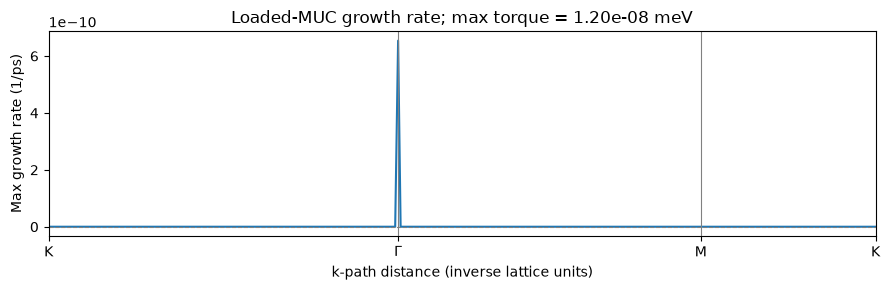

In [12]:
growth = np.max(epsilon_path.imag / hbar, axis=1)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(path_distance, growth)
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
for tick in path_ticks[1:-1]:
    ax.axvline(tick, color="gray", linewidth=0.8)
ax.set_xticks(path_ticks, path_labels)
ax.set(xlim=(path_ticks[0], path_ticks[-1]), xlabel="k-path distance (inverse lattice units)",
       ylabel="Max growth rate (1/ps)",
       title=f"Loaded-MUC growth rate; max torque = {max_torque:.2e} meV")
plt.tight_layout()
plt.show()